# Equipo 19 · Entrenamiento end-to-end con dos máscaras: El Meslouhi y Arnold

En el Avance 4 se reentrenó Endo-STTN con C3VDv2 usando dos máscaras de reflejos: **El Meslouhi (2011)** (corrida 4)
y **Arnold (2010)** (variante A1). Las dos rellenaron casi igual de bien. Este notebook responde la siguiente
pregunta: **¿cuál de los dos sirve mejor al estimador de profundidad cuando ambas redes se entrenan juntas?**

```
clip de 5 frames ─► máscara (Meslouhi o Arnold) ─► Endo-STTN reentrenado con ESA máscara ─► relleno en los reflejos
                                                     (entrenable)                                  │
                               profundidad real ◄── pérdida SI-log ◄── AF-SfMLearner (entrenable) ◄─┘
```

**Se corre una vez por máscara**, en sesiones separadas: primero con `MASCARA = "meslouhi"` y luego con
`MASCARA = "arnold"`. Lo que comparten las dos corridas (los datos preparados y el modelo C) se guarda en Drive y la
segunda corrida lo reutiliza. La comparación entre máscaras aparece sola cuando ya existen los modelos de las dos.

| Modelo | Endo-STTN | Estimador de profundidad | Frames que ve el estimador |
|---|---|---|---|
| A | — | AF-SfMLearner (SCARED), sin ajustar | originales |
| C | — | ajustado con frames originales | originales |
| D · máscara | reentrenado con esa máscara, **congelado** | ajustado con frames limpios | limpios por Endo-STTN congelado |
| **E · máscara** | reentrenado con esa máscara, **entrenado junto con el estimador** | **ajustado junto con Endo-STTN** | limpios por su Endo-STTN ajustado |

Las comparaciones importantes son tres:
- **D vs E**, con cada máscara: ¿ayuda entrenar las dos redes juntas?
- **E · Meslouhi vs E · Arnold**: ¿con qué máscara se obtiene mejor profundidad al final?
- **D · Meslouhi vs D · Arnold**: la misma pregunta, pero sin entrenamiento conjunto.

Todo el código del equipo está en este notebook. Solo se descargan las **arquitecturas publicadas** de Endo-STTN y de
AF-SfMLearner (sus repositorios oficiales, fijados a la versión probada) y los pesos.

## 0. Antes de empezar

**Colab Pro:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución →* **A100 GPU** (o L4) y **RAM alta**.
El modelo E guarda en memoria las activaciones de las dos redes, así que conviene la GPU más grande disponible.
Después: *Entorno de ejecución → Ejecutar todas*.

**En Google Drive** se necesita:

| Ruta (ajustable en la celda siguiente) | Qué es |
|---|---|
| `MyDrive/Equipo19/raw/*.zip` | ZIPs de C3VDv2 con `rgb/` y `depth/` de los 7 videos de la división |
| `MyDrive/endo_corrida4/modelos/gen_mejor.pth` | Endo-STTN reentrenado con El Meslouhi (corrida 4, iteración 1750) |
| `MyDrive/Equipo19/re_entrenar_endo/arnold_variaciones/A1/modelos/gen_mejor.pth` | Endo-STTN reentrenado con Arnold (A1, iteración 1750) |
| `MyDrive/Equipo19/Model_trained_end_to_end.zip` | Pesos de AF-SfMLearner (SCARED). Si no está, se descarga |

Los dos `gen_mejor.pth` se eligieron con el **mismo criterio**: el checkpoint con menor error de relleno en
validación, medido con los huecos de **su propia** máscara. Si el de la corrida 4 está en el Drive de otra persona,
cópialo a tu Drive y ajusta la ruta.

**Si Colab se desconecta**, vuelve a ejecutar todo. Cada paso guarda su resultado en Drive y se salta si ya está
hecho. Un entrenamiento interrumpido sí empieza de nuevo.

In [1]:
from pathlib import Path
import os, sys, json, random, re, shutil, subprocess, time, zipfile

# ---------- Ajusta aquí ----------
MASCARA = "meslouhi"         # "meslouhi" o "arnold": una corrida completa del notebook por máscara
SEMILLA = 0
EPOCAS = 15

MYDRIVE = Path("/content/drive/MyDrive")
CARPETA_RAW = MYDRIVE / "Equipo19" / "raw"                   # ZIPs de C3VDv2
SALIDA = MYDRIVE / "Equipo19" / "end_to_end_mascaras"       # todo lo que produce este notebook
PESOS_ENDO = {                                               # Endo-STTN reentrenado con cada máscara (Avance 4)
    "meslouhi": MYDRIVE / "endo_corrida4" / "modelos" / "gen_mejor.pth",
    "arnold": MYDRIVE / "Equipo19" / "re_entrenar_endo" / "arnold_variaciones" / "A1" / "modelos" / "gen_mejor.pth",
}
# La misma división del Avance 4. Ningún Endo-STTN vio los videos de prueba.
DIVISION = {
    "entrenamiento": ["c2_cecum_t1_v1", "c2_rectum_t1_v1", "c2_transverse1_t1_v1", "c1_ascending_t3_v1"],
    "validacion": ["c2_sigmoid_t3_v2"],
    "prueba": ["c2_descending_t4_v2", "c2_descending_t4_v3"],
}
PASO, MAX_FRAMES = 5, 300    # 1 de cada 5 frames, máximo 300 por video (como en el Avance 2)

# Entrenamiento: lo mismo para C, D y E, para que las diferencias se deban solo al método
LOTE_D = 8                   # frames por lote (C y D)
LOTE_E = 2                   # clips de 5 frames por lote (E); bájalo a 1 si sale "CUDA out of memory"
LR, LR_STTN = 1e-4, 1e-5     # decoder de profundidad (su encoder usa LR/10) y Endo-STTN (el del Avance 4)
PESO_HUECO = 1.0             # E: reconstruir tejido sano con la máscara desplazada
PESO_ANCLA = 0.0             # E: parecerse al relleno del Endo-STTN congelado (p. ej. 0.5)
STTN_CAPAS = "todo"          # E: "todo" o "transformer" (encoder y decoder de Endo-STTN congelados)
BLOQUE = 60                  # frames por bloque al limpiar un video con Endo-STTN
# ---------------------------------

assert MASCARA in PESOS_ENDO, f"MASCARA debe ser una de {list(PESOS_ENDO)}"
OTRA = [m for m in PESOS_ENDO if m != MASCARA][0]
print(f"Esta corrida: máscara {MASCARA}, semilla {SEMILLA}, {EPOCAS} épocas")

Esta corrida: máscara meslouhi, semilla 0, 15 épocas


In [3]:
assert "google.colab" in sys.modules, "Este notebook es para Google Colab"
from google.colab import drive
drive.mount("/content/drive")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "tabulate"], check=True)

LOCAL = Path("/content")
EXTERNOS = LOCAL / "externos"
DATOS = LOCAL / "datos_e2e"              # copia local de los frames (leer de Drive al entrenar es lento)
MODELOS = SALIDA / "modelos"             # los modelos se guardan directo en Drive
RESULTADOS = SALIDA / f"resultados_s{SEMILLA}"
for d in (EXTERNOS, DATOS, MODELOS, RESULTADOS):
    d.mkdir(parents=True, exist_ok=True)

# Arquitecturas publicadas, fijadas a la versión que usa el equipo
REPOS = {"Endo-STTN": ("https://github.com/endomapper/Endo-STTN.git", "9419a6c"),
         "AF-SfMLearner": ("https://github.com/ShuweiShao/AF-SfMLearner.git", "53d01a4")}
for nombre, (url, commit) in REPOS.items():
    if not (EXTERNOS / nombre).exists():
        subprocess.run(["git", "clone", "-q", url, str(EXTERNOS / nombre)], check=True)
        subprocess.run(["git", "-C", str(EXTERNOS / nombre), "checkout", "-q", commit], check=True)
    if str(EXTERNOS / nombre) not in sys.path:
        sys.path.append(str(EXTERNOS / nombre))

# Pesos de AF-SfMLearner entrenados en SCARED: punto de partida de C, D y E
PESOS_SCARED = EXTERNOS / "pesos_scared"
if not (PESOS_SCARED / "encoder.pth").exists():
    z = MYDRIVE / "Equipo19" / "Model_trained_end_to_end.zip"
    if not z.exists():
        import gdown
        z = EXTERNOS / "Model_trained_end_to_end.zip"
        gdown.download(id="1ZogZ5nQsfLhFAQGG_UE9A5R_osypLZf1", output=str(z), quiet=True)
    shutil.unpack_archive(str(z), str(EXTERNOS / "pesos_zip"))
    origen = next((EXTERNOS / "pesos_zip").rglob("encoder.pth")).parent
    PESOS_SCARED.mkdir(exist_ok=True)
    for f in ("encoder.pth", "depth.pth"):
        shutil.copy(origen / f, PESOS_SCARED / f)

assert PESOS_ENDO[MASCARA].exists(), f"No encuentro el Endo-STTN de {MASCARA}: {PESOS_ENDO[MASCARA]}"
print("Endo-STTN", MASCARA, ":", PESOS_ENDO[MASCARA])
print("AF-SfMLearner :", PESOS_SCARED)
print("Resultados en :", SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Endo-STTN meslouhi : /content/drive/MyDrive/endo_corrida4/modelos/gen_mejor.pth
AF-SfMLearner : /content/externos/pesos_scared
Resultados en : /content/drive/MyDrive/Equipo19/end_to_end_mascaras


## 1. Herramientas

Cuatro celdas con todas las funciones. No entrenan nada; solo las definen.

**1a. Lectura de C3VDv2 y máscaras de reflejos.** Cada ZIP trae `rgb/` (color) y `depth/` (profundidad real, TIFF
de 16 bits, 0–65535 = 0–100 mm). Las dos máscaras se calculan **igual que al reentrenar Endo-STTN** en el Avance 4:
sobre el frame a 288×288. Después se llevan a 320×256, la resolución del estimador. Así cada Endo-STTN recibe el mismo
tipo de hueco con el que aprendió a rellenar.

In [4]:
import cv2
import numpy as np

ANCHO, ALTO = 320, 256       # entrada de AF-SfMLearner (C3VD es 5:4, igual que 320x256)
LADO = 288                   # entrada de Endo-STTN
PROF_MAX_MM = 100.0


def indice(nombre):
    """Número de frame dentro del nombre de archivo ('0042_color.png' -> 42)."""
    m = re.search(r"(\d+)", Path(nombre).stem)
    return int(m.group(1)) if m else None


def listar_pares(zf):
    """Pares (indice, ruta_rgb, ruta_depth) presentes en las dos carpetas, ordenados."""
    nombres = zf.namelist()
    rgb = {indice(n): n for n in nombres if n.startswith("rgb/") and n.lower().endswith((".png", ".jpg"))}
    dep = {indice(n): n for n in nombres if n.startswith("depth/") and n.lower().endswith((".tiff", ".tif", ".png"))}
    if not rgb or not dep:
        raise ValueError(f"El ZIP no tiene rgb/ y depth/ (carpetas: {sorted({n.split('/')[0] for n in nombres})})")
    return [(i, rgb[i], dep[i]) for i in sorted(set(rgb) & set(dep) - {None})]


def leer_rgb(zf, ruta):
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(zf.read(ruta), np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def leer_profundidad(zf, ruta):
    """Profundidad en mm (float32). 0 = sin dato (incluye píxeles saturados)."""
    d = cv2.imdecode(np.frombuffer(zf.read(ruta), np.uint8), cv2.IMREAD_UNCHANGED)
    d = d[..., 0] if d.ndim == 3 else d
    if d.dtype == np.uint16:
        mm = d.astype(np.float32) * (PROF_MAX_MM / 65535.0)
        mm[d == 65535] = 0
        return mm
    return d.astype(np.float32)


def _srgb_a_xyz(img):
    lin = np.where(img <= 0.04045, img / 12.92, ((img + 0.055) / 1.055) ** 2.4)
    m = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    return lin @ m.T


def _dilatar_1px(m):
    return cv2.dilate(m.astype(np.uint8), np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], np.uint8)).astype(bool)


def mascara_meslouhi(rgb):
    """El Meslouhi et al. (2011), la de los autores de Endo-STTN: realce por min/max, CIE-XYZ,
    reflejo donde Y >= Y/(X+Y+Z), dilatación de 1 px."""
    img = rgb.astype(np.float64) / 255
    mn, mx = img.min(-1), img.max(-1)
    s = np.divide(mn, mx, out=np.zeros_like(mn), where=mx > 0)
    xyz = _srgb_a_xyz(s[..., None] * img)
    suma = xyz.sum(-1)
    y = np.divide(xyz[..., 1], suma, out=np.full_like(suma, np.inf), where=suma > 0)
    return _dilatar_1px(xyz[..., 1] >= y)


def mascara_arnold(rgb, t_abs=240, t_cand=200, t_rel=1.2, mediana=31):
    """Arnold et al. (2010), versión simplificada: detector absoluto (muy brillante, corregido por el balance
    de color) + detector relativo (más brillante que una imagen "sin reflejos" estimada), dilatación de 1 px."""
    img = rgb.astype(np.float32)
    gris = img @ np.array([0.2989, 0.5870, 0.1140], np.float32)
    p95 = lambda c: max(float(np.percentile(c, 95)), 1.0)
    r_g, r_b = p95(img[..., 1]) / p95(gris), p95(img[..., 2]) / p95(gris)
    sobre = lambda t: (img[..., 1] > r_g * t) | (img[..., 2] > r_b * t) | (gris > t)
    candidatos = cv2.dilate(sobre(t_cand).astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    sin_reflejos = cv2.medianBlur(cv2.inpaint(rgb, candidatos, 5, cv2.INPAINT_TELEA), mediana).astype(np.float32)
    relativo = ((img / (sin_reflejos + 1)).max(-1) > t_rel) & (gris > t_cand * 0.75)
    return _dilatar_1px(sobre(t_abs) | relativo)


METODOS = {"meslouhi": mascara_meslouhi, "arnold": mascara_arnold}


def mascara(rgb_320, metodo):
    """Máscara a 320x256 calculada sobre el frame a 288x288, como al reentrenar Endo-STTN."""
    m = METODOS[metodo](cv2.resize(rgb_320, (LADO, LADO), interpolation=cv2.INTER_AREA))
    return cv2.resize(m.astype(np.uint8), (ANCHO, ALTO), interpolation=cv2.INTER_NEAREST).astype(bool)

**1b. AF-SfMLearner.** Carga y guardado de pesos, predicción de profundidad en mm, la pérdida **scale-invariant log**
(Eigen et al., 2014; solo importa la forma relativa de la profundidad, no la escala) y las métricas de evaluación con
*median scaling*.

In [5]:
import warnings
import torch
import torch.nn.functional as F
warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")   # aviso de 'pretrained' en AF-SfMLearner
import networks                                  # AF-SfMLearner
from model.sttn import InpaintGenerator          # Endo-STTN

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PROF_MIN, PROF_MAX = 0.1, PROF_MAX_MM


def cargar_estimador(carpeta):
    enc = networks.ResnetEncoder(18, False)
    sd = torch.load(Path(carpeta) / "encoder.pth", map_location=DEVICE)
    enc.load_state_dict({k: v for k, v in sd.items() if k in enc.state_dict()})
    dec = networks.DepthDecoder(num_ch_enc=enc.num_ch_enc, scales=range(4))
    dec.load_state_dict(torch.load(Path(carpeta) / "depth.pth", map_location=DEVICE))
    return enc.to(DEVICE), dec.to(DEVICE)


def guardar_estimador(enc, dec, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    sd = enc.state_dict()
    sd.update(height=ALTO, width=ANCHO)
    torch.save(sd, carpeta / "encoder.pth")
    torch.save(dec.state_dict(), carpeta / "depth.pth")


def a_tensor(rgb_uint8):
    """(B,H,W,3) uint8 -> (B,3,H,W) en [0,1]."""
    return torch.from_numpy(np.array(rgb_uint8)).permute(0, 3, 1, 2).float().div(255).to(DEVICE)


def predecir(enc, dec, x):
    """Profundidad en mm, (B,1,H,W). Igual que disp_to_depth de Monodepth2/AF-SfMLearner."""
    disp = dec(enc(x))[("disp", 0)]
    min_disp, max_disp = 1 / PROF_MAX, 1 / PROF_MIN
    return 1 / (min_disp + (max_disp - min_disp) * disp)


def perdida_si_log(pred, gt):
    """Scale-invariant log por imagen, sobre los píxeles con profundidad real."""
    perdidas = []
    for p, g in zip(pred, gt):
        valido = g > 0
        if valido.sum() < 10:
            continue
        d = torch.log(p[valido]) - torch.log(g[valido])
        perdidas.append((d ** 2).mean() - d.mean() ** 2)
    return torch.stack(perdidas).mean()


def metricas(pred, gt, region=None):
    """Métricas con median scaling. La escala se calcula con toda la imagen y luego se mide en la región."""
    valido = (gt > 0) & (gt <= PROF_MAX)
    if valido.sum() < 10:
        return None
    escala = np.median(gt[valido]) / np.median(pred[valido])
    if region is not None:
        valido &= region
        if valido.sum() < 10:
            return None
    p, g = pred[valido].astype(np.float64), gt[valido].astype(np.float64)
    p = np.clip(p * escala, PROF_MIN, PROF_MAX)
    ratio = np.maximum(p / g, g / p)
    return {"abs_rel": float(np.mean(np.abs(p - g) / g)), "sq_rel": float(np.mean((p - g) ** 2 / g)),
            "rmse": float(np.sqrt(np.mean((p - g) ** 2))),
            "rmse_log": float(np.sqrt(np.mean((np.log(p) - np.log(g)) ** 2))), "a1": float(np.mean(ratio < 1.25))}


@torch.no_grad()
def predecir_video(enc, dec, rgb):
    enc.eval(); dec.eval()
    return np.concatenate([predecir(enc, dec, a_tensor(rgb[i:i + 16]))[:, 0].cpu().numpy()
                           for i in range(0, len(rgb), 16)])

**1c. Endo-STTN.** Hay dos formas de usarlo:
- `limpiar_video`: la **inferencia oficial** de Endo-STTN (frames vecinos + frames de referencia), sin gradiente.
  Sirve para limpiar los videos con Endo-STTN congelado (modelo D) y para validar y evaluar E.
- `rellenar`: el mismo pre y posprocesamiento, pero **diferenciable** (en PyTorch). Es lo que permite que el error de
  profundidad llegue hasta Endo-STTN durante el entrenamiento de E.

`desplazar` mueve la máscara 56 px a 320×256 (los 50 px a 288×288 del entrenamiento original). Así el hueco cae sobre
tejido sano, cuyo color sí se conoce: es la *pseudo ground truth* de Endo-STTN.

In [6]:
NEIGHBOR_STRIDE, REF_LENGTH = 5, 10   # como en Endo-STTN/test.py
DESPLAZAMIENTO = 56


def cargar_endo(pesos):
    sd = torch.load(pesos, map_location=DEVICE)
    sd = {k.removeprefix("module."): v for k, v in sd.get("netG", sd).items()}
    modelo = InpaintGenerator().to(DEVICE)
    modelo.load_state_dict(sd)
    return modelo.eval()


@torch.no_grad()
def limpiar_bloque(modelo, rgb, mask):
    """rgb (T,H,W,3) uint8, mask (T,H,W) bool -> (T,H,W,3) uint8 con los reflejos rellenados."""
    T, H, W = mask.shape
    f = np.stack([cv2.resize(x, (LADO, LADO), interpolation=cv2.INTER_AREA) for x in rgb])
    m = np.stack([cv2.resize(x.astype(np.uint8), (LADO, LADO), interpolation=cv2.INTER_NEAREST) for x in mask])
    feats = torch.from_numpy(f).permute(0, 3, 1, 2).float().div(255).mul(2).sub(1).to(DEVICE)   # [-1,1]
    masks = torch.from_numpy(m).float().unsqueeze(1).to(DEVICE)
    enc = modelo.encoder(feats * (1 - masks))
    _, c, fh, fw = enc.shape
    enc = enc.view(1, T, c, fh, fw)
    acum, cuenta = np.zeros((T, LADO, LADO, 3), np.float32), np.zeros(T, np.float32)
    for k in range(0, T, NEIGHBOR_STRIDE):
        vec = list(range(max(0, k - NEIGHBOR_STRIDE), min(T, k + NEIGHBOR_STRIDE + 1)))
        ids = vec + [i for i in range(0, T, REF_LENGTH) if i not in vec]
        pred = torch.tanh(modelo.decoder(modelo.infer(enc[0, ids], masks[ids])[:len(vec)]))
        pred = ((pred + 1) / 2).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy() * 255
        for i, idx in enumerate(vec):
            acum[idx] += pred[i]
            cuenta[idx] += 1
    pred = acum / cuenta[:, None, None, None]
    out = rgb.copy()
    for t in range(T):
        relleno = cv2.resize(pred[t], (W, H), interpolation=cv2.INTER_LINEAR)
        out[t][mask[t]] = np.clip(relleno[mask[t]], 0, 255).astype(np.uint8)
    return out


def limpiar_video(modelo, rgb, mask):
    rgb, mask = np.asarray(rgb), np.asarray(mask)
    return np.concatenate([limpiar_bloque(modelo, rgb[i:i + BLOQUE], mask[i:i + BLOQUE])
                           for i in range(0, len(rgb), BLOQUE)])


def desplazar(m, dx=DESPLAZAMIENTO):
    """Máscara desplazada dx px a la derecha."""
    out = torch.zeros_like(m)
    out[..., dx:] = m[..., :-dx]
    return out


def rellenar(sttn, x, hueco):
    """Relleno diferenciable. x (B,T,3,H,W) en [0,1], hueco (B,T,1,H,W) -> (B,T,3,H,W)."""
    B, T, _, H, W = x.shape
    f = F.interpolate(x.flatten(0, 1), (LADO, LADO), mode="area") * 2 - 1
    m = F.interpolate(hueco.flatten(0, 1), (LADO, LADO), mode="nearest")
    out = sttn((f * (1 - m)).view(B, T, 3, LADO, LADO), m.view(B, T, 1, LADO, LADO))
    out = F.interpolate((out + 1) / 2, (H, W), mode="bilinear", align_corners=False)
    return out.view(B, T, 3, H, W)


def l1_en(a, b, region):
    """L1 media dentro de una región (B,T,1,H,W); 0 si la región está vacía."""
    return ((a - b).abs() * region).sum() / (region.sum() * a.shape[2]).clamp(min=1)

**1d. Datos en disco y conjuntos de entrenamiento.** Cada video queda como arreglos `.npy` en una copia local y otra
en Drive (`end_to_end_mascaras/datos/`). Si una sesión nueva no los tiene en local, los trae de Drive.
- `Frames`: frames sueltos, para C y D. Los aumentos son volteo horizontal y brillo ±10 %.
- `Clips`: clips de 5 frames, para E (la longitud con la que se entrenó Endo-STTN). La mitad de las veces son
  consecutivos y la otra mitad al azar, ordenados. Se voltea el clip completo, y el brillo se aplica **después** de la
  limpieza (igual que en D).

In [7]:
def ruta(video, nombre):
    return DATOS / video / f"{nombre}.npy"


def existe(video, nombre):
    """¿Ya existe? Si solo está en Drive (de otra sesión), lo copia a local."""
    en_drive = SALIDA / "datos" / video / f"{nombre}.npy"
    if not ruta(video, nombre).exists() and en_drive.exists():
        ruta(video, nombre).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(en_drive, ruta(video, nombre))
    return ruta(video, nombre).exists()


def guardar(video, nombre, arr):
    """Guarda en local y en Drive (primero con otro nombre, para no dejar archivos a medias)."""
    ruta(video, nombre).parent.mkdir(parents=True, exist_ok=True)
    np.save(ruta(video, nombre), arr)
    destino = SALIDA / "datos" / video
    destino.mkdir(parents=True, exist_ok=True)
    shutil.copy(ruta(video, nombre), destino / f"{nombre}.tmp")
    os.replace(destino / f"{nombre}.tmp", destino / f"{nombre}.npy")


def cargar(video, nombre):
    assert existe(video, nombre), f"Falta {nombre}.npy de {video}"
    return np.load(ruta(video, nombre), mmap_mode="r")


class Frames(torch.utils.data.Dataset):
    def __init__(self, videos, entrada):
        self.datos = [(cargar(v, entrada), cargar(v, "depth")) for v in videos]
        self.indices = [(k, i) for k, (rgb, _) in enumerate(self.datos) for i in range(len(rgb))]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, n):
        k, i = self.indices[n]
        rgb = np.array(self.datos[k][0][i], np.float32) / 255
        prof = np.array(self.datos[k][1][i], np.float32)
        if random.random() < 0.5:
            rgb, prof = rgb[:, ::-1], prof[:, ::-1]
        rgb = np.clip(rgb * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05), 0, 1)
        return torch.from_numpy(rgb.transpose(2, 0, 1).copy()), torch.from_numpy(prof.copy())[None]


class Clips(torch.utils.data.Dataset):
    def __init__(self, videos, mascara, T=5):
        self.datos = [(cargar(v, "rgb"), cargar(v, "depth"), cargar(v, f"mask_{mascara}"),
                       cargar(v, f"rgb_limpio_{mascara}")) for v in videos]
        self.T = T
        self.indices = [(k, i) for k, d in enumerate(self.datos) for i in range(0, len(d[0]) - T + 1, T)]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, n):
        k, i = self.indices[n]
        rgb, prof, mask, limpio = self.datos[k]
        ids = sorted(random.sample(range(len(rgb)), self.T)) if random.random() < 0.5 else list(range(i, i + self.T))
        x = np.stack([rgb[j] for j in ids]).astype(np.float32) / 255
        lim = np.stack([limpio[j] for j in ids]).astype(np.float32) / 255
        m = np.stack([mask[j] for j in ids]).astype(np.float32)
        g = np.stack([prof[j] for j in ids]).astype(np.float32)
        if random.random() < 0.5:
            x, lim, m, g = x[:, :, ::-1], lim[:, :, ::-1], m[:, :, ::-1], g[:, :, ::-1]
        brillo = np.array([random.uniform(0.9, 1.1), random.uniform(-0.05, 0.05)], np.float32)
        t = lambda a: torch.from_numpy(np.ascontiguousarray(a))
        return t(x.transpose(0, 3, 1, 2)), t(lim.transpose(0, 3, 1, 2)), t(m[:, None]), t(g[:, None]), t(brillo)


def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    return torch.Generator().manual_seed(s)


print("Dispositivo:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu (sin GPU: será muy lento)")

Dispositivo: NVIDIA A100-SXM4-80GB


## 2. Preparar los datos (se comparte entre las dos corridas)

De cada video se toma 1 de cada 5 frames (como máximo 300), se pasan a 320×256 y se guardan el color, la profundidad
real y **las dos máscaras**. Las dos máscaras se calculan siempre, incluso en la corrida de una sola, porque la
evaluación mide el error en una **región común** a todos los modelos (la unión de las dos). Si no se hiciera así,
cada modelo se mediría en píxeles distintos y los números no serían comparables (la misma lección de los huecos en el
Avance 4).

La primera corrida prepara los datos. La segunda los encuentra en Drive y se salta este paso.

In [8]:
VIDEOS = [v for g in DIVISION.values() for v in g]
prep = {"paso": PASO, "max_frames": MAX_FRAMES, "division": DIVISION}
f_prep = SALIDA / "preparacion.json"
if f_prep.exists():
    assert json.load(open(f_prep)) == prep, (
        f"Los datos de {SALIDA} se prepararon con otra configuración: {json.load(open(f_prep))}. "
        "Regresa PASO, MAX_FRAMES y DIVISION a esos valores, o usa otra carpeta SALIDA.")
else:
    json.dump(prep, open(f_prep, "w"), indent=2)


def zip_de(video):
    """ZIP de un video en CARPETA_RAW: nombre exacto, o con sufijo de Drive ("-007", " (1)")."""
    if (CARPETA_RAW / f"{video}.zip").exists():
        return CARPETA_RAW / f"{video}.zip"
    candidatos = [z for z in CARPETA_RAW.glob(f"{video}*.zip") if not z.stem[len(video)].isalnum()
                  and z.stem[len(video)] != "_"]
    assert len(candidatos) == 1, f"Para {video} hay {len(candidatos)} ZIPs en {CARPETA_RAW}: {candidatos}"
    return candidatos[0]


for k, v in enumerate(VIDEOS, 1):
    if all(existe(v, n) for n in ["rgb", "depth", "mask_meslouhi", "mask_arnold"]):
        print(f"[{k}/{len(VIDEOS)}] {v}: ya preparado")
        continue
    with zipfile.ZipFile(zip_de(v)) as zf:
        pares = listar_pares(zf)[::PASO][:MAX_FRAMES or None]
        rgbs, profs = [], []
        for _, r, d in pares:
            rgbs.append(cv2.resize(leer_rgb(zf, r), (ANCHO, ALTO), interpolation=cv2.INTER_AREA))
            profs.append(cv2.resize(leer_profundidad(zf, d), (ANCHO, ALTO),
                                    interpolation=cv2.INTER_NEAREST).astype(np.float16))
    rgb = np.stack(rgbs)
    guardar(v, "rgb", rgb)
    guardar(v, "depth", np.stack(profs))
    for m in METODOS:
        guardar(v, f"mask_{m}", np.stack([mascara(x, m) for x in rgb]))
    print(f"[{k}/{len(VIDEOS)}] {v}: {len(rgb)} frames")

import pandas as pd
from IPython.display import Markdown, display
grupo = {v: g for g, vs in DIVISION.items() for v in vs}
display(pd.DataFrame([{"video": v, "grupo": grupo[v], "frames": len(cargar(v, "rgb")),
                       **{f"% reflejos {m}": round(100 * float(np.mean(cargar(v, f"mask_{m}"))), 2) for m in METODOS}}
                      for v in VIDEOS]).set_index("video"))

[1/7] c2_cecum_t1_v1: ya preparado
[2/7] c2_rectum_t1_v1: ya preparado
[3/7] c2_transverse1_t1_v1: ya preparado
[4/7] c1_ascending_t3_v1: ya preparado
[5/7] c2_sigmoid_t3_v2: ya preparado
[6/7] c2_descending_t4_v2: ya preparado
[7/7] c2_descending_t4_v3: ya preparado


,grupo,frames,% reflejos meslouhi,% reflejos arnold
video,,,,
c2_cecum_t1_v1,entrenamiento,61,5.63,8.09
c2_rectum_t1_v1,entrenamiento,31,11.20,11.08
c2_transverse1_t1_v1,entrenamiento,81,2.51,4.68
c1_ascending_t3_v1,entrenamiento,52,2.66,15.56
c2_sigmoid_t3_v2,validacion,45,0.22,0.72
c2_descending_t4_v2,prueba,26,1.50,5.64
c2_descending_t4_v3,prueba,26,2.05,9.13


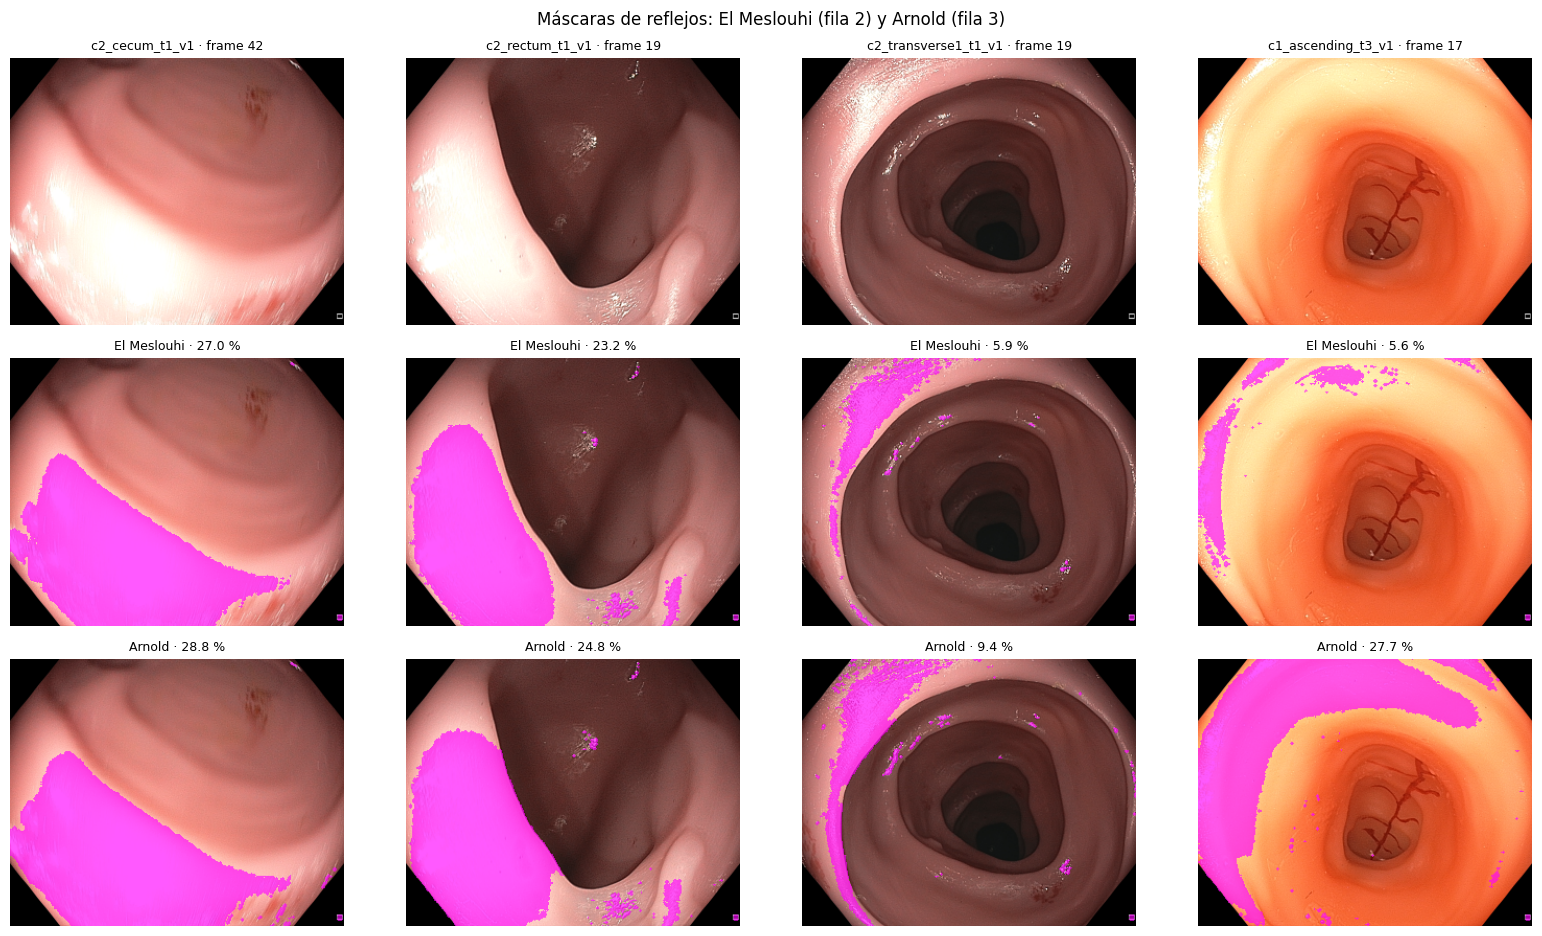

In [9]:
import matplotlib.pyplot as plt

# Las dos máscaras en un frame de cada video de entrenamiento (magenta = reflejo detectado)
magenta = np.array([255, 0, 255], np.uint8)
con_mascara = lambda img, m: np.where(m[..., None], (0.35 * img + 0.65 * magenta).astype(np.uint8), img)
fig, ax = plt.subplots(3, len(DIVISION["entrenamiento"]), figsize=(4 * len(DIVISION["entrenamiento"]), 9.5),
                       squeeze=False)
for j, v in enumerate(DIVISION["entrenamiento"]):
    mm, ma = cargar(v, "mask_meslouhi"), cargar(v, "mask_arnold")
    i = int(np.argmax((np.asarray(mm) | np.asarray(ma)).reshape(len(mm), -1).mean(1)))
    rgb = cargar(v, "rgb")[i]
    paneles = [(rgb, f"{v} · frame {i}"), (con_mascara(rgb, mm[i]), f"El Meslouhi · {100 * mm[i].mean():.1f} %"),
               (con_mascara(rgb, ma[i]), f"Arnold · {100 * ma[i].mean():.1f} %")]
    for r, (img, t) in enumerate(paneles):
        ax[r, j].imshow(img); ax[r, j].set_title(t, fontsize=9); ax[r, j].axis("off")
plt.suptitle("Máscaras de reflejos: El Meslouhi (fila 2) y Arnold (fila 3)"); plt.tight_layout()
plt.savefig(RESULTADOS / "mascaras.png", dpi=80, bbox_inches="tight"); plt.show()

## 3. Frames limpios con el Endo-STTN reentrenado, congelado (esta máscara)

El Endo-STTN reentrenado con esta máscara limpia todos los videos **sin entrenarse**. Usa la máscara con la que se
entrenó. El resultado (`rgb_limpio_<máscara>`) tiene tres usos:
1. Entrenar el estimador del modelo **D**.
2. Servir de referencia para medir cuánto cambia el relleno cuando Endo-STTN se entrena junto con el estimador (E).
3. Servir de ancla opcional en la pérdida de E (`PESO_ANCLA`).

In [10]:
endo = cargar_endo(PESOS_ENDO[MASCARA])
for k, v in enumerate(VIDEOS, 1):
    if existe(v, f"rgb_limpio_{MASCARA}"):
        print(f"[{k}/{len(VIDEOS)}] {v}: ya limpio")
        continue
    t0 = time.time()
    guardar(v, f"rgb_limpio_{MASCARA}", limpiar_video(endo, cargar(v, "rgb"), cargar(v, f"mask_{MASCARA}")))
    print(f"[{k}/{len(VIDEOS)}] {v}: limpio ({time.time() - t0:.0f} s)")
del endo; torch.cuda.empty_cache()

[1/7] c2_cecum_t1_v1: limpio (5 s)
[2/7] c2_rectum_t1_v1: limpio (1 s)
[3/7] c2_transverse1_t1_v1: limpio (2 s)
[4/7] c1_ascending_t3_v1: limpio (1 s)
[5/7] c2_sigmoid_t3_v2: limpio (1 s)
[6/7] c2_descending_t4_v2: limpio (0 s)
[7/7] c2_descending_t4_v3: limpio (0 s)


## 4. Estimadores C y D (sin entrenamiento conjunto)

Los dos parten de AF-SfMLearner con los pesos de SCARED y usan la misma configuración. Solo cambian los frames de
entrada:
- **C:** frames originales. No depende de la máscara, así que se entrena una sola vez y la segunda corrida lo reutiliza.
- **D · máscara:** frames limpios por el Endo-STTN congelado de esta máscara.

En cada época se mide el AbsRel en el video de validación y se guarda la mejor época.

In [11]:
@torch.no_grad()
def validar_estimador(enc, dec, entrada):
    vals = []
    for v in DIVISION["validacion"]:
        pred, prof = predecir_video(enc, dec, cargar(v, entrada)), cargar(v, "depth")
        vals += [r["abs_rel"] for p, g in zip(pred, prof) if (r := metricas(p, np.asarray(g, np.float32)))]
    return float(np.mean(vals))


def terminado(nombre):
    f = MODELOS / nombre / "historial.json"
    return f.exists() and "mejor_abs_rel_val" in json.load(open(f))


def entrenar_estimador(nombre, entrada):
    if terminado(nombre):
        print(f"{nombre}: ya entrenado, se reutiliza"); return
    salida = MODELOS / nombre
    gen = fijar_semilla(SEMILLA)
    datos = Frames(DIVISION["entrenamiento"], entrada)
    carga = torch.utils.data.DataLoader(datos, batch_size=LOTE_D, shuffle=True, drop_last=True, generator=gen)
    enc, dec = cargar_estimador(PESOS_SCARED)
    opt = torch.optim.Adam([{"params": enc.parameters(), "lr": LR / 10}, {"params": dec.parameters(), "lr": LR}])
    historial = {"entrada": entrada, "semilla": SEMILLA, "division": DIVISION, "epocas": []}
    mejor = validar_estimador(enc, dec, entrada)
    historial["epocas"].append({"epoca": 0, "abs_rel_val": mejor})
    guardar_estimador(enc, dec, salida)
    print(f"{nombre} ({len(datos)} frames) · época 0 (SCARED): AbsRel validación {mejor:.4f}")
    for ep in range(1, EPOCAS + 1):
        t0, perdidas = time.time(), []
        enc.train(); dec.train()
        for x, gt in carga:
            loss = perdida_si_log(predecir(enc, dec, x.to(DEVICE)), gt.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            perdidas.append(loss.item())
        val = validar_estimador(enc, dec, entrada)
        historial["epocas"].append({"epoca": ep, "perdida": float(np.mean(perdidas)), "abs_rel_val": val})
        marca = ""
        if val < mejor:
            mejor, marca = val, "  <- mejor, guardado"
            guardar_estimador(enc, dec, salida)
        print(f"  época {ep}: pérdida {np.mean(perdidas):.4f} | AbsRel validación {val:.4f} | {time.time() - t0:.0f} s{marca}")
        json.dump(historial, open(salida / "historial.json", "w"), indent=2)
    historial["mejor_abs_rel_val"] = mejor
    json.dump(historial, open(salida / "historial.json", "w"), indent=2)


entrenar_estimador(f"C_s{SEMILLA}", "rgb")
entrenar_estimador(f"D_{MASCARA}_s{SEMILLA}", f"rgb_limpio_{MASCARA}")

C_s0: ya entrenado, se reutiliza
D_meslouhi_s0 (225 frames) · época 0 (SCARED): AbsRel validación 0.4076
  época 1: pérdida 0.1491 | AbsRel validación 0.1705 | 2 s  <- mejor, guardado
  época 2: pérdida 0.0309 | AbsRel validación 0.1109 | 2 s  <- mejor, guardado
  época 3: pérdida 0.0179 | AbsRel validación 0.1022 | 2 s  <- mejor, guardado
  época 4: pérdida 0.0136 | AbsRel validación 0.0929 | 2 s  <- mejor, guardado
  época 5: pérdida 0.0118 | AbsRel validación 0.1019 | 1 s
  época 6: pérdida 0.0098 | AbsRel validación 0.0881 | 2 s  <- mejor, guardado
  época 7: pérdida 0.0092 | AbsRel validación 0.1080 | 1 s
  época 8: pérdida 0.0092 | AbsRel validación 0.0969 | 1 s
  época 9: pérdida 0.0076 | AbsRel validación 0.1065 | 1 s
  época 10: pérdida 0.0070 | AbsRel validación 0.0803 | 2 s  <- mejor, guardado
  época 11: pérdida 0.0070 | AbsRel validación 0.1015 | 1 s
  época 12: pérdida 0.0070 | AbsRel validación 0.1069 | 1 s
  época 13: pérdida 0.0065 | AbsRel validación 0.0931 | 1 s
  ép

## 5. Modelo E: Endo-STTN y estimador entrenados juntos (esta máscara)

En cada paso de entrenamiento:
1. Se toma la máscara de reflejos real (`m`) y se crea un **pseudo-hueco**: la misma máscara desplazada sobre tejido
   sano, cuya respuesta se conoce.
2. Endo-STTN rellena los dos huecos con `rellenar`, que es diferenciable.
3. El relleno se pega **solo** dentro de los reflejos: `x_limpio = x·(1−m) + relleno·m`.
4. AF-SfMLearner predice la profundidad de `x_limpio`.
5. Se calcula la pérdida total:

$$\mathcal{L} = \mathcal{L}_{SI}(\text{profundidad}) + \lambda_h\,\mathcal{L}_{hueco} + \lambda_a\,\mathcal{L}_{ancla}$$

6. Un solo `loss.backward()` actualiza **las dos redes**: el error de profundidad también ajusta a Endo-STTN.

$\mathcal{L}_{hueco}$ obliga a Endo-STTN a seguir reconstruyendo tejido real. Sin ese término podría "pintar" cualquier
patrón que le facilite el trabajo al estimador. Al validar se mide el **cambio del relleno** (0–255) respecto al
Endo-STTN congelado del paso 3. Si crece mucho mientras el AbsRel baja, hay que sospechar ese atajo.

In [12]:
@torch.no_grad()
def validar_conjunto(sttn, enc, dec):
    """AbsRel de validación y cambio medio del relleno respecto al Endo-STTN congelado (0-255)."""
    sttn.eval()
    absrel, cambio = [], []
    for v in DIVISION["validacion"]:
        mask = np.asarray(cargar(v, f"mask_{MASCARA}"))
        limpio = limpiar_video(sttn, cargar(v, "rgb"), mask)
        if mask.any():
            cambio.append(np.abs(limpio.astype(np.int16) - cargar(v, f"rgb_limpio_{MASCARA}"))[mask].mean())
        pred = predecir_video(enc, dec, limpio)
        absrel += [r["abs_rel"] for p, g in zip(pred, cargar(v, "depth")) if (r := metricas(p, np.asarray(g, np.float32)))]
    return float(np.mean(absrel)), float(np.mean(cambio)) if cambio else float("nan")


def guardar_conjunto(sttn, enc, dec, carpeta):
    guardar_estimador(enc, dec, carpeta)
    torch.save({"netG": sttn.state_dict()}, carpeta / "sttn.pth")     # mismo formato que gen_mejor.pth


def entrenar_conjunto():
    nombre = f"E_{MASCARA}_s{SEMILLA}"
    salida, frames_e = MODELOS / nombre, f"rgb_e2e_{MASCARA}_s{SEMILLA}"
    if terminado(nombre) and all(existe(v, frames_e) for v in DIVISION["validacion"] + DIVISION["prueba"]):
        print(f"{nombre}: ya entrenado, se reutiliza"); return
    if not terminado(nombre):
        gen = fijar_semilla(SEMILLA)
        datos = Clips(DIVISION["entrenamiento"], MASCARA)
        carga = torch.utils.data.DataLoader(datos, batch_size=LOTE_E, shuffle=True, drop_last=True, generator=gen)
        sttn = cargar_endo(PESOS_ENDO[MASCARA])
        if STTN_CAPAS == "transformer":
            for p in [*sttn.encoder.parameters(), *sttn.decoder.parameters()]:
                p.requires_grad = False
        enc, dec = cargar_estimador(PESOS_SCARED)
        opt = torch.optim.Adam([
            {"params": enc.parameters(), "lr": LR / 10},
            {"params": dec.parameters(), "lr": LR},
            {"params": [p for p in sttn.parameters() if p.requires_grad], "lr": LR_STTN, "betas": (0.0, 0.99)},
        ])
        historial = {"mascara": MASCARA, "pesos_endo": str(PESOS_ENDO[MASCARA]), "semilla": SEMILLA,
                     "sttn_capas": STTN_CAPAS, "peso_hueco": PESO_HUECO, "peso_ancla": PESO_ANCLA,
                     "lote": LOTE_E, "lr": LR, "lr_sttn": LR_STTN, "division": DIVISION, "epocas": []}
        mejor, cambio = validar_conjunto(sttn, enc, dec)
        historial["epocas"].append({"epoca": 0, "abs_rel_val": mejor, "cambio_relleno_val": cambio})
        guardar_conjunto(sttn, enc, dec, salida)
        print(f"{nombre} ({len(datos)} clips de 5 frames) · época 0: AbsRel validación {mejor:.4f}")
        for ep in range(1, EPOCAS + 1):
            t0, suma = time.time(), {"prof": [], "hueco": [], "ancla": [], "total": []}
            sttn.train(); enc.train(); dec.train()
            for x, limpio, m, gt, brillo in carga:
                x, limpio, m, gt, brillo = (t.to(DEVICE) for t in (x, limpio, m, gt, brillo))
                pseudo = desplazar(m) * (1 - m)                       # hueco sobre tejido sano
                relleno = rellenar(sttn, x, (m + pseudo).clamp(max=1))
                x_limpio = x * (1 - m) + relleno * m                   # solo se pega en los reflejos
                a, b = brillo[:, 0].view(-1, 1, 1, 1, 1), brillo[:, 1].view(-1, 1, 1, 1, 1)
                entrada = (x_limpio * a + b).clamp(0, 1).flatten(0, 1)
                l_prof = perdida_si_log(predecir(enc, dec, entrada), gt.flatten(0, 1))
                l_hueco = l1_en(relleno, x, pseudo)
                l_ancla = l1_en(relleno, limpio, m)
                loss = l_prof + PESO_HUECO * l_hueco + PESO_ANCLA * l_ancla
                opt.zero_grad(); loss.backward(); opt.step()
                for k, v in zip(suma, (l_prof, l_hueco, l_ancla, loss)):
                    suma[k].append(v.item())
            val, cambio = validar_conjunto(sttn, enc, dec)
            fila = {"epoca": ep, **{f"perdida_{k}": float(np.mean(v)) for k, v in suma.items()},
                    "abs_rel_val": val, "cambio_relleno_val": cambio}
            historial["epocas"].append(fila)
            marca = ""
            if val < mejor:
                mejor, marca = val, "  <- mejor, guardado"
                guardar_conjunto(sttn, enc, dec, salida)
            print(f"  época {ep}: prof {fila['perdida_prof']:.4f} | hueco {fila['perdida_hueco']:.4f} | "
                  f"AbsRel validación {val:.4f} | cambio del relleno {cambio:.1f}/255 | {time.time() - t0:.0f} s{marca}")
            json.dump(historial, open(salida / "historial.json", "w"), indent=2)
        historial["mejor_abs_rel_val"] = mejor
        json.dump(historial, open(salida / "historial.json", "w"), indent=2)
        del sttn, enc, dec, opt; torch.cuda.empty_cache()

    # Frames limpiados por el Endo-STTN ajustado (mejor época), para evaluar E
    sttn = cargar_endo(salida / "sttn.pth")
    for v in DIVISION["validacion"] + DIVISION["prueba"]:
        guardar(v, frames_e, limpiar_video(sttn, cargar(v, "rgb"), cargar(v, f"mask_{MASCARA}")))
    print(f"{nombre}: listo ->", salida)


entrenar_conjunto()

E_meslouhi_s0 (44 clips de 5 frames) · época 0: AbsRel validación 0.4076
  época 1: prof 0.1841 | hueco 0.0253 | AbsRel validación 0.1932 | cambio del relleno 4.0/255 | 10 s  <- mejor, guardado
  época 2: prof 0.0466 | hueco 0.0212 | AbsRel validación 0.1379 | cambio del relleno 5.5/255 | 11 s  <- mejor, guardado
  época 3: prof 0.0278 | hueco 0.0206 | AbsRel validación 0.1050 | cambio del relleno 6.8/255 | 10 s  <- mejor, guardado
  época 4: prof 0.0236 | hueco 0.0199 | AbsRel validación 0.1406 | cambio del relleno 7.7/255 | 10 s
  época 5: prof 0.0193 | hueco 0.0195 | AbsRel validación 0.1048 | cambio del relleno 9.6/255 | 10 s  <- mejor, guardado
  época 6: prof 0.0175 | hueco 0.0169 | AbsRel validación 0.1145 | cambio del relleno 10.1/255 | 10 s
  época 7: prof 0.0151 | hueco 0.0178 | AbsRel validación 0.1124 | cambio del relleno 10.6/255 | 10 s
  época 8: prof 0.0155 | hueco 0.0174 | AbsRel validación 0.0952 | cambio del relleno 11.7/255 | 10 s  <- mejor, guardado
  época 9: prof 

## 6. Curvas de entrenamiento

Se muestran todos los modelos que ya existen en Drive. En la segunda corrida aparecen los de las dos máscaras. El
color indica la máscara (C, sin Endo-STTN, va en azul) y el tipo de línea distingue D (punteada) de E (continua).

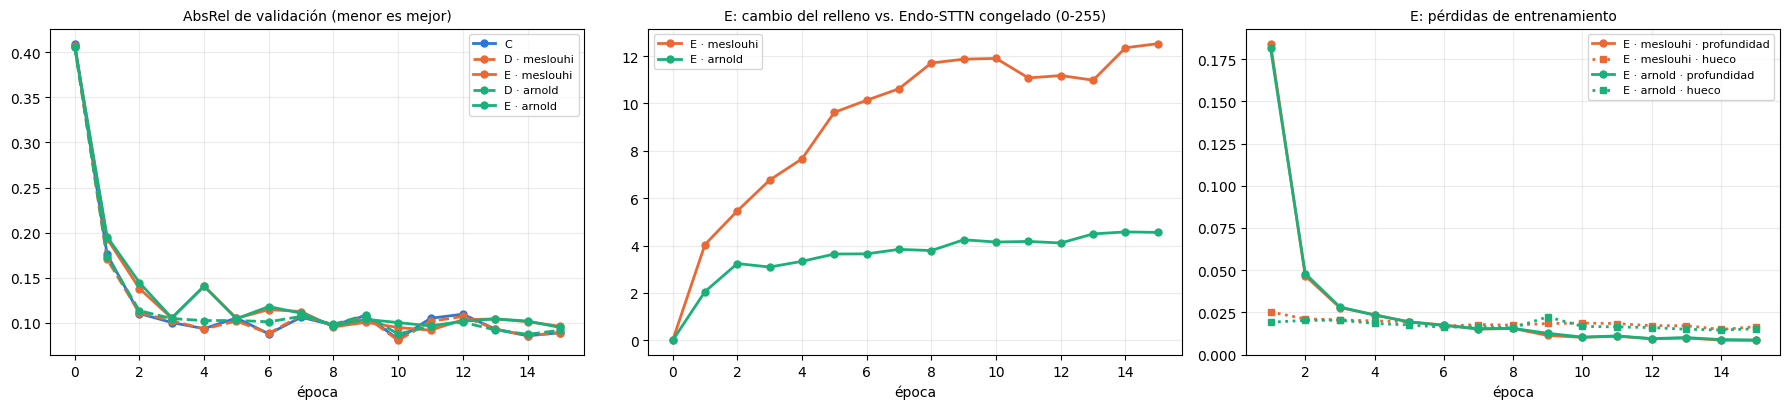

In [13]:
MASCARAS_LISTAS = [m for m in PESOS_ENDO if terminado(f"E_{m}_s{SEMILLA}") and terminado(f"D_{m}_s{SEMILLA}")]
COLOR = {"C": "#2a78d6", "meslouhi": "#eb6834", "arnold": "#1baf7a", "A": "#6250d6"}
estilo = lambda nombre: dict(color=COLOR[nombre.split("_")[1]] if "_" in nombre else COLOR[nombre],
                             ls="--" if nombre.startswith("D_") else "-", lw=2, marker="o", ms=5)
hist = {}
for nombre in ["C"] + [f"{t}_{m}" for m in PESOS_ENDO for t in ("D", "E")]:
    f = MODELOS / f"{nombre}_s{SEMILLA}" / "historial.json"
    if f.exists():
        hist[nombre] = json.load(open(f))["epocas"]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for nombre, ep in hist.items():
    ax[0].plot([e["epoca"] for e in ep], [e["abs_rel_val"] for e in ep], label=nombre.replace("_", " · "), **estilo(nombre))
    if nombre.startswith("E_"):
        ax[1].plot([e["epoca"] for e in ep], [e["cambio_relleno_val"] for e in ep], label=nombre.replace("_", " · "), **estilo(nombre))
        ax[2].plot([e["epoca"] for e in ep[1:]], [e["perdida_prof"] for e in ep[1:]], label=f"{nombre.replace('_', ' · ')} · profundidad", **estilo(nombre))
        ax[2].plot([e["epoca"] for e in ep[1:]], [e["perdida_hueco"] for e in ep[1:]], label=f"{nombre.replace('_', ' · ')} · hueco",
                   **{**estilo(nombre), "ls": ":", "marker": "s"})
titulos = ["AbsRel de validación (menor es mejor)", "E: cambio del relleno vs. Endo-STTN congelado (0-255)",
           "E: pérdidas de entrenamiento"]
for a, t in zip(ax, titulos):
    a.set_title(t, fontsize=10); a.set_xlabel("época"); a.grid(alpha=0.25)
    if a.lines:
        a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTADOS / "curvas.png", dpi=90); plt.show()

## 7. Evaluación en los videos de prueba

Los videos de prueba (`c2_descending_t4` v2 y v3) no los vio ningún Endo-STTN ni ningún estimador. Cada modelo
recibe sus propios frames (tabla del inicio) y se mide contra la profundidad real en cuatro regiones:

| Región | Para qué |
|---|---|
| `imagen` | Toda la imagen: comparable entre todos los modelos |
| `reflejos (unión)` | Píxeles marcados por **cualquiera** de las dos máscaras: la región común para comparar máscaras |
| `reflejos meslouhi`, `reflejos arnold` | Dentro de cada máscara, como dato extra |

Las pruebas de **Wilcoxon** son pareadas por frame:
- **D vs E** (una cola): ¿E tiene menor AbsRel?
- **Meslouhi vs Arnold** (dos colas): ¿hay diferencia entre máscaras?

In [14]:
modelos = {"A": (PESOS_SCARED, "rgb"), "C": (MODELOS / f"C_s{SEMILLA}", "rgb")}
for m in PESOS_ENDO:
    modelos[f"D_{m}"] = (MODELOS / f"D_{m}_s{SEMILLA}", f"rgb_limpio_{m}")
    modelos[f"E_{m}"] = (MODELOS / f"E_{m}_s{SEMILLA}", f"rgb_e2e_{m}_s{SEMILLA}")
modelos = {k: (p, e) for k, (p, e) in modelos.items()
           if (k == "A" or terminado(Path(p).name)) and all(existe(v, e) for v in DIVISION["prueba"])}
print("Modelos a evaluar:", list(modelos))

filas = []
for nombre, (pesos, entrada) in modelos.items():
    enc, dec = cargar_estimador(pesos)
    for v in DIVISION["prueba"]:
        pred, prof = predecir_video(enc, dec, cargar(v, entrada)), cargar(v, "depth")
        mm, ma = cargar(v, "mask_meslouhi"), cargar(v, "mask_arnold")
        for i in range(len(pred)):
            regiones = {"imagen": None, "reflejos (unión)": mm[i] | ma[i],
                        "reflejos meslouhi": np.asarray(mm[i]), "reflejos arnold": np.asarray(ma[i])}
            for reg, region in regiones.items():
                if r := metricas(pred[i], np.asarray(prof[i], np.float32), region):
                    filas.append({"modelo": nombre, "video": v, "frame": i, "region": reg, **r})
    del enc, dec
df = pd.DataFrame(filas)
df.to_csv(RESULTADOS / "evaluacion_por_frame.csv", index=False)
orden = [k for k in modelos]
resumen = df.groupby(["region", "modelo"])[["abs_rel", "sq_rel", "rmse", "rmse_log", "a1"]].mean().round(4)
resumen.to_csv(RESULTADOS / "evaluacion_resumen.csv")


def wilcoxon(a, b, region, alternativa):
    from scipy.stats import wilcoxon as w
    t = df[df.region == region].pivot_table(index=["video", "frame"], columns="modelo", values="abs_rel")
    if a not in t or b not in t:
        return None
    t = t[[a, b]].dropna()
    return {"comparación": f"{a} vs {b}", "región": region, "H1": "b < a" if alternativa == "greater" else "a ≠ b",
            "frames": len(t), "mediana a−b": round(float((t[a] - t[b]).median()), 4),
            "p": float(w(t[a], t[b], alternative=alternativa).pvalue)}


pruebas = []
for reg in ["imagen", "reflejos (unión)"]:
    for m in PESOS_ENDO:
        pruebas += [wilcoxon("C", f"D_{m}", reg, "greater"), wilcoxon(f"D_{m}", f"E_{m}", reg, "greater")]
    pruebas += [wilcoxon("D_meslouhi", "D_arnold", reg, "two-sided"), wilcoxon("E_meslouhi", "E_arnold", reg, "two-sided")]
pruebas = pd.DataFrame([p for p in pruebas if p])

with open(RESULTADOS / "evaluacion_resumen.md", "w") as f:
    f.write(f"Videos de prueba: {', '.join(DIVISION['prueba'])} · semilla {SEMILLA}\n\n")
    for reg in ["imagen", "reflejos (unión)", "reflejos meslouhi", "reflejos arnold"]:
        if reg in resumen.index.get_level_values(0):
            f.write(f"### Región: {reg}\n\n{resumen.loc[reg].reindex([o for o in orden if o in resumen.loc[reg].index]).to_markdown()}\n\n")
    if len(pruebas):
        f.write("### Wilcoxon pareado por frame (AbsRel)\n\n" + pruebas.to_markdown(index=False) + "\n")
display(Markdown(open(RESULTADOS / "evaluacion_resumen.md").read()))

Modelos a evaluar: ['A', 'C', 'D_meslouhi', 'E_meslouhi', 'D_arnold', 'E_arnold']


Videos de prueba: c2_descending_t4_v2, c2_descending_t4_v3 · semilla 0

### Región: imagen

| modelo     |   abs_rel |   sq_rel |    rmse |   rmse_log |     a1 |
|:-----------|----------:|---------:|--------:|-----------:|-------:|
| A          |    0.3963 |   6.7745 | 18.3791 |     0.5119 | 0.3875 |
| C          |    0.1228 |   1.1037 |  7.8095 |     0.177  | 0.8109 |
| D_meslouhi |    0.1217 |   1.0456 |  7.5582 |     0.1722 | 0.8126 |
| E_meslouhi |    0.1121 |   0.819  |  6.3775 |     0.157  | 0.8388 |
| D_arnold   |    0.124  |   1.0724 |  7.611  |     0.1752 | 0.8053 |
| E_arnold   |    0.1218 |   1.0121 |  7.4384 |     0.171  | 0.8107 |

### Región: reflejos (unión)

| modelo     |   abs_rel |   sq_rel |   rmse |   rmse_log |     a1 |
|:-----------|----------:|---------:|-------:|-----------:|-------:|
| A          |    0.814  |   7.8217 | 8.2623 |     0.6083 | 0.1811 |
| C          |    0.0741 |   0.1445 | 1.5372 |     0.0986 | 0.9648 |
| D_meslouhi |    0.0811 |   0.1621 | 1.6079 |     0.1031 | 0.9547 |
| E_meslouhi |    0.0781 |   0.1786 | 1.714  |     0.1041 | 0.9402 |
| D_arnold   |    0.0945 |   0.1944 | 1.6014 |     0.1178 | 0.9254 |
| E_arnold   |    0.1018 |   0.2143 | 1.7475 |     0.128  | 0.9151 |

### Región: reflejos meslouhi

| modelo     |   abs_rel |   sq_rel |   rmse |   rmse_log |     a1 |
|:-----------|----------:|---------:|-------:|-----------:|-------:|
| A          |    0.96   |   9.6468 | 8.769  |     0.6599 | 0.1169 |
| C          |    0.0834 |   0.1659 | 1.4749 |     0.0994 | 0.9626 |
| D_meslouhi |    0.081  |   0.1821 | 1.5507 |     0.0977 | 0.9545 |
| E_meslouhi |    0.0836 |   0.2346 | 1.8021 |     0.1058 | 0.9039 |
| D_arnold   |    0.0933 |   0.166  | 1.383  |     0.1066 | 0.9581 |
| E_arnold   |    0.1009 |   0.2136 | 1.6724 |     0.1211 | 0.9044 |

### Región: reflejos arnold

| modelo     |   abs_rel |   sq_rel |   rmse |   rmse_log |     a1 |
|:-----------|----------:|---------:|-------:|-----------:|-------:|
| A          |    0.814  |   7.8217 | 8.2623 |     0.6083 | 0.1811 |
| C          |    0.0741 |   0.1445 | 1.5372 |     0.0986 | 0.9648 |
| D_meslouhi |    0.0811 |   0.1621 | 1.6079 |     0.1031 | 0.9547 |
| E_meslouhi |    0.0781 |   0.1786 | 1.714  |     0.1041 | 0.9402 |
| D_arnold   |    0.0945 |   0.1944 | 1.6014 |     0.1178 | 0.9254 |
| E_arnold   |    0.1018 |   0.2143 | 1.7475 |     0.128  | 0.9151 |

### Wilcoxon pareado por frame (AbsRel)

| comparación              | región           | H1    |   frames |   mediana a−b |           p |
|:-------------------------|:-----------------|:------|---------:|--------------:|------------:|
| C vs D_meslouhi          | imagen           | b < a |       52 |        0.0002 | 0.0235551   |
| D_meslouhi vs E_meslouhi | imagen           | b < a |       52 |        0.0089 | 1.85746e-10 |
| C vs D_arnold            | imagen           | b < a |       52 |        0.0019 | 0.539898    |
| D_arnold vs E_arnold     | imagen           | b < a |       52 |       -0.0001 | 0.164919    |
| D_meslouhi vs D_arnold   | imagen           | a ≠ b |       52 |        0.0015 | 0.512018    |
| E_meslouhi vs E_arnold   | imagen           | a ≠ b |       52 |       -0.0102 | 1.10027e-07 |
| C vs D_meslouhi          | reflejos (unión) | b < a |       52 |       -0.0049 | 0.998414    |
| D_meslouhi vs E_meslouhi | reflejos (unión) | b < a |       52 |        0.0035 | 0.0193544   |
| C vs D_arnold            | reflejos (unión) | b < a |       52 |       -0.0163 | 0.999951    |
| D_arnold vs E_arnold     | reflejos (unión) | b < a |       52 |       -0.0099 | 0.988324    |
| D_meslouhi vs D_arnold   | reflejos (unión) | a ≠ b |       52 |       -0.005  | 0.0441537   |
| E_meslouhi vs E_arnold   | reflejos (unión) | a ≠ b |       52 |       -0.0225 | 2.0249e-08  |


## 8. Resultados visuales de impainting

**Relleno.** Se muestra el frame de prueba con más reflejos y, para cada máscara lista, el relleno del Endo-STTN
congelado (D) junto al del Endo-STTN ajustado (E), con zoom. Si E gana en profundidad pero su relleno ya no parece
tejido, la mejora viene de que el relleno "codifica" profundidad y no de un mejor inpainting.

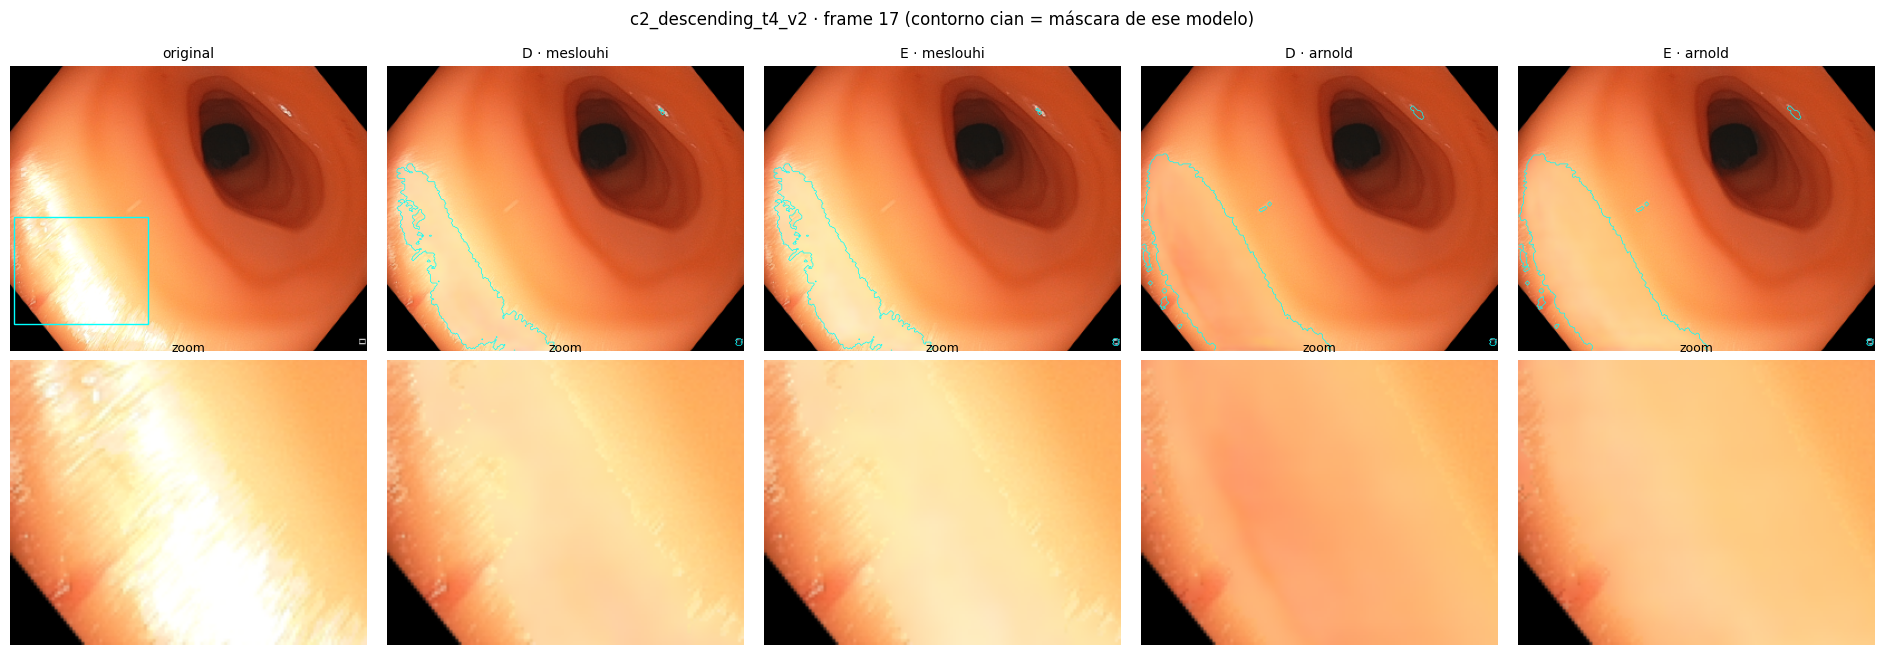

meslouhi: |E − D| medio dentro de los reflejos de este frame = 5.8/255
arnold: |E − D| medio dentro de los reflejos de este frame = 12.6/255


In [15]:
video = DIVISION["prueba"][0]
rgb = cargar(video, "rgb")
union = np.asarray(cargar(video, "mask_meslouhi")) | np.asarray(cargar(video, "mask_arnold"))
i = int(np.argmax(union.reshape(len(union), -1).mean(1)))
ys, xs = np.nonzero(union[i]) if union[i].any() else (np.array([128]), np.array([160]))
y0 = int(np.clip(np.median(ys) - 48, 0, ALTO - 96)); x0 = int(np.clip(np.median(xs) - 60, 0, ANCHO - 120))
zoom = lambda a: a[y0:y0 + 96, x0:x0 + 120]

paneles = [(rgb[i], "original", None)]
for m in PESOS_ENDO:
    mask_m = np.asarray(cargar(video, f"mask_{m}"))[i]
    for t, nombre in (("D", f"rgb_limpio_{m}"), ("E", f"rgb_e2e_{m}_s{SEMILLA}")):
        if existe(video, nombre) and terminado(f"{t}_{m}_s{SEMILLA}"):
            img = cargar(video, nombre)[i]
            paneles.append((img, f"{t} · {m}", mask_m))
fig, ax = plt.subplots(2, len(paneles), figsize=(3.8 * len(paneles), 6.5), squeeze=False)
for j, (img, t, mk) in enumerate(paneles):
    ax[0, j].imshow(img); ax[0, j].set_title(t, fontsize=10)
    ax[1, j].imshow(zoom(img)); ax[1, j].set_title("zoom", fontsize=9)
    if mk is not None:
        ax[0, j].contour(mk, [0.5], colors="cyan", linewidths=0.5)
ax[0, 0].add_patch(plt.Rectangle((x0, y0), 120, 96, fill=False, color="cyan"))
for a in ax.ravel():
    a.axis("off")
plt.suptitle(f"{video} · frame {i} (contorno cian = máscara de ese modelo)", y=1.0); plt.tight_layout()
plt.savefig(RESULTADOS / "relleno.png", dpi=90, bbox_inches="tight"); plt.show()

for m in MASCARAS_LISTAS:
    d, e = cargar(video, f"rgb_limpio_{m}")[i], cargar(video, f"rgb_e2e_{m}_s{SEMILLA}")[i]
    mk = np.asarray(cargar(video, f"mask_{m}"))[i]
    if mk.any():
        print(f"{m}: |E − D| medio dentro de los reflejos de este frame = {np.abs(e.astype(int) - d.astype(int))[mk].mean():.1f}/255")

**estimación de profundidad.** En el mismo frame: predicción de cada modelo (arriba) y error relativo contra la profundidad real
(abajo; más oscuro = menos error). El contorno cian es la unión de las dos máscaras de reflejos.

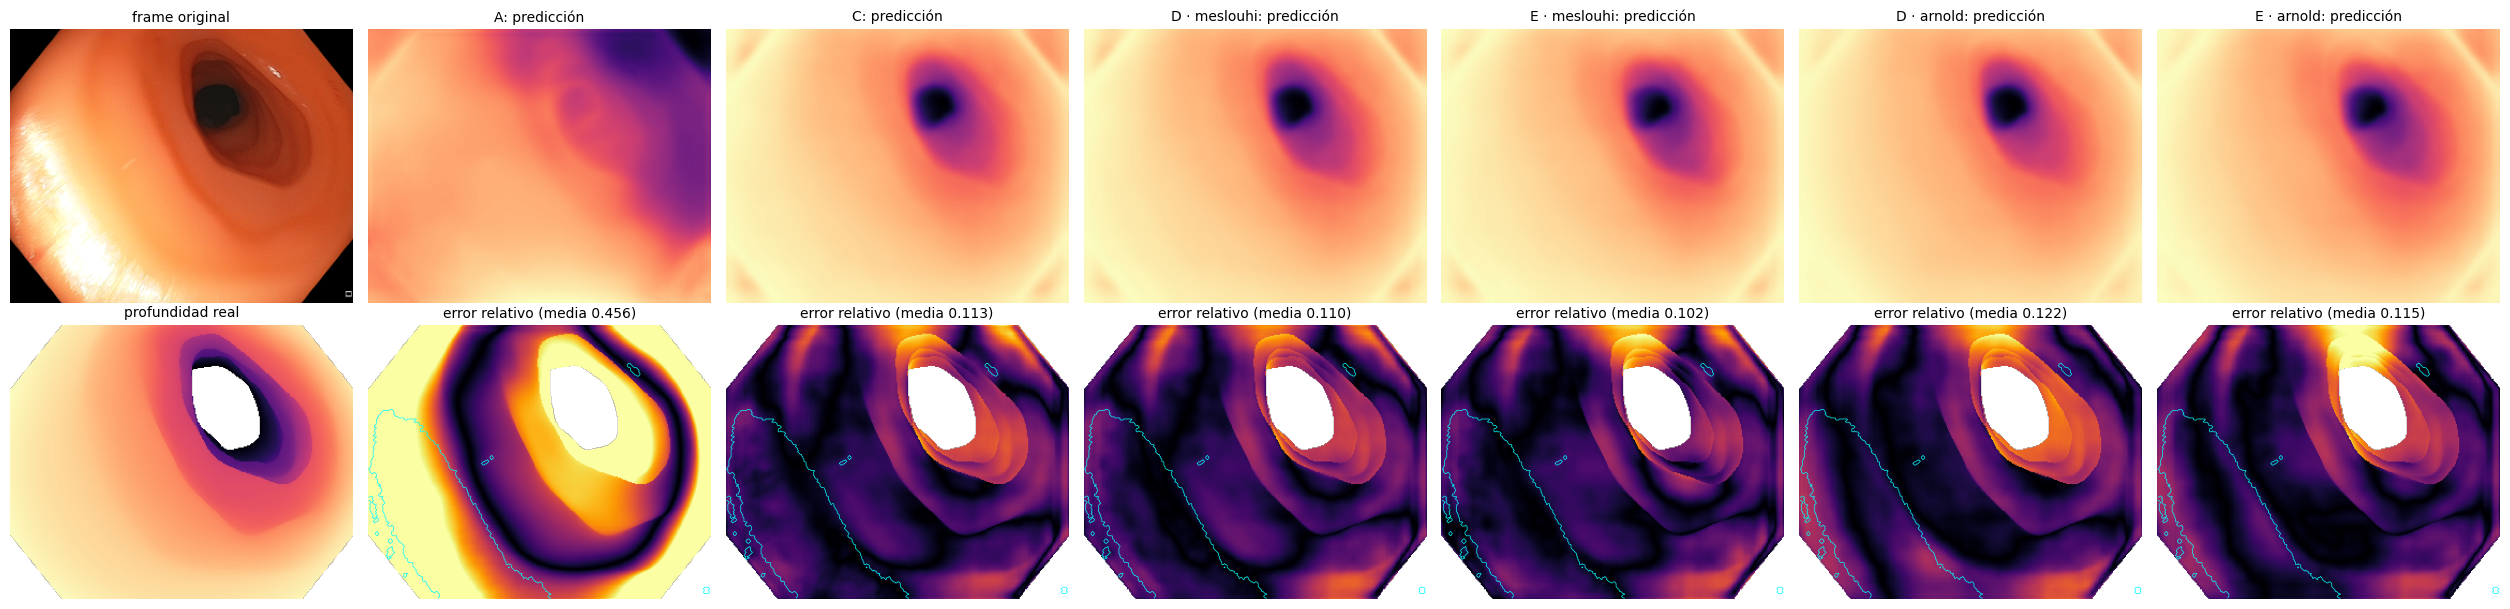

Resultados guardados en /content/drive/MyDrive/Equipo19/end_to_end_mascaras/resultados_s0


In [16]:
g = np.asarray(cargar(video, "depth")[i], np.float32); valido = g > 0
fig, ax = plt.subplots(2, len(modelos) + 1, figsize=(3.6 * (len(modelos) + 1), 6.2), squeeze=False)
ax[0, 0].imshow(rgb[i]); ax[0, 0].set_title("frame original", fontsize=10)
ax[1, 0].imshow(np.where(valido, g, np.nan), cmap="magma_r"); ax[1, 0].set_title("profundidad real", fontsize=10)
for j, (nombre, (pesos, entrada)) in enumerate(modelos.items(), 1):
    enc, dec = cargar_estimador(pesos)
    p = predecir_video(enc, dec, cargar(video, entrada)[i:i + 1])[0]
    p = p * np.median(g[valido]) / np.median(p[valido])
    err = np.where(valido, np.abs(p - g) / np.maximum(g, 1e-3), np.nan)
    ax[0, j].imshow(p, cmap="magma_r"); ax[0, j].set_title(f"{nombre.replace('_', ' · ')}: predicción", fontsize=10)
    ax[1, j].imshow(err, cmap="inferno", vmin=0, vmax=0.5)
    ax[1, j].set_title(f"error relativo (media {np.nanmean(err):.3f})", fontsize=10)
    ax[1, j].contour(union[i], [0.5], colors="cyan", linewidths=0.5)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.savefig(RESULTADOS / "profundidad.png", dpi=90, bbox_inches="tight"); plt.show()
print("Resultados guardados en", RESULTADOS)

## 9. Cómo leer los resultados

Con **una sola máscara** lista (primera corrida), la pregunta es **D vs E**:
- **E < D en AbsRel** (Wilcoxon p < 0.05), sin empeorar en la imagen completa y con un relleno que sigue pareciendo
  tejido: entrenar las dos redes juntas ayuda.
- **E < D, pero el relleno se ve artificial** (cambio del relleno alto, |E − D| grande): Endo-STTN aprendió a "pintar
  pistas" para el estimador. Repite con `PESO_HUECO = 2` o `PESO_ANCLA = 0.5` (y otra carpeta `SALIDA` o borrando
  `modelos/E_...`).
- **E ≈ D**: el relleno congelado ya era suficiente. Puedes probar `STTN_CAPAS = "transformer"`.
- **E > D**: el ajuste conjunto desestabiliza; baja `LR_STTN` a `1e-6`.

Con **las dos máscaras** listas (segunda corrida), además:
- **E · meslouhi vs E · arnold** en `reflejos (unión)` e `imagen`: si p ≥ 0.05, las dos máscaras son equivalentes
  también para la profundidad, igual que en el relleno del Avance 4.
- Compara también **D · meslouhi vs D · arnold**: si la diferencia entre máscaras solo aparece en E, la causa es el
  entrenamiento conjunto y no la máscara en sí.

**Advertencias:**
- La prueba tiene un solo segmento (`c2_descending_t4`, 2 videos), y los frames de un video están correlacionados.
  Los valores p de Wilcoxon exageran la certeza.
- Para concluir algo, repite con `SEMILLA = 1`: cada máscara otra vez, en su propia sesión. C se vuelve a entrenar
  para la nueva semilla.